# Interview Analysis Visualizations

Three key visualizations showcasing the pipeline results.

In [1]:
import json
import textwrap
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.path import Path
import seaborn as sns
import networkx as nx
import plotly.graph_objects as go
import plotly.express as px
from collections import defaultdict



with open('output/stage_1/aggregate_data.json', 'r') as f:
    agg_data = json.load(f)

with open('outputs/stage_2/pattern_findings.json', 'r') as f:
    findings_data = json.load(f)

with open('codebook.yaml', 'r') as f:
    codebook = yaml.safe_load(f)

# interview group 
BSC_INTERVIEWS = ['I01', 'I07', 'I08', 'I09', 'I10', 'I11', 'I12']
MSC_INTERVIEWS = ['I02', 'I03', 'I04', 'I05', 'I06', 'I13','I14', 'I15', 'I16', 'I17']

In [2]:
# finding_interview_edges and finding_info for network graph
finding_interview_edges = defaultdict(lambda: defaultdict(int))
finding_info = {}

for finding in findings_data['findings']:
    finding_type = finding['finding_type']
    title = finding['title'][:50] + '...' if len(finding['title']) > 50 else finding['title']
    confidence = finding.get('confidence', 'moderate')

    interviews_cited = set()
    for quote_id in finding['quote_ids']:
        interview_id = quote_id.split('-')[0]
        interviews_cited.add(interview_id)
        finding_interview_edges[finding_type][interview_id] += 1

    finding_info[finding_type] = {
        'title': title,
        'confidence': confidence,
        'full_title': finding['title'],
        'interviews': interviews_cited,
        'quote_count': len(finding['quote_ids'])
    }

# Code → theme mapping from the codebook
code_to_theme = {}      # {code_id: (theme_id, theme_name)}
theme_names = {}        # {theme_id: theme_name}
theme_ids = []

for theme_id, theme_data in codebook.items():
    if isinstance(theme_data, dict) and 'codes' in theme_data:
        theme_id = str(theme_id)
        theme_name = theme_data.get('name', f'Theme {theme_id}')
        theme_names[theme_id] = theme_name
        if theme_id not in theme_ids:
            theme_ids.append(theme_id)
        for code_id in theme_data['codes']:
            code_to_theme[code_id] = (theme_id, theme_name)

# Flows for the Sankey diagram
theme_code_flows = defaultdict(set)      # {(theme_display, code): {quote_ids}}
code_finding_flows = defaultdict(set)    # {(code, finding_type): {quote_ids}}

for finding in findings_data['findings']:
    finding_type = finding['finding_type']
    quote_ids = finding['quote_ids']
    codes_involved_actual = finding.get('codes_involved_actual', finding.get('codes_involved', []))

    for code in codes_involved_actual:
        if code in code_to_theme:
            theme_id, theme_name = code_to_theme[code]
            theme_display = f'Theme {theme_id}: {theme_name}'
            theme_code_flows[(theme_display, code)].update(quote_ids)
            code_finding_flows[(code, finding_type)].update(quote_ids)

# GLOBAL COLOUR SCHEME (used by every plot in the notebook)
#   - one base colour per theme
#   - each code = a different shade of its theme's colour
THEME_BASE = {'1': '#3B78B5',    # blue
              '2': '#3FA07A',    # green
              '3': '#8E63B5'}    # purple
_EXTRA_BASES = ['#D9903D', '#C55A6E', '#7A8B99']   # only used if >3 themes
FINDING_COLOR = '#6B7785'                          # neutral slate for finding types
NEUTRAL = '#BBBBBB'

def _shade(hex_color, f):
    """f < 0 darkens (mix with black), f > 0 lightens (mix with white)."""
    c = np.array(mcolors.to_rgb(hex_color))
    c = c * (1 + f) if f < 0 else c * (1 - f) + f
    return mcolors.to_hex(np.clip(c, 0, 1))

THEME_COLOR = {}
for i, tid in enumerate(theme_ids):
    THEME_COLOR[tid] = THEME_BASE.get(tid, _EXTRA_BASES[i % len(_EXTRA_BASES)])

CODE_COLOR = {}
for tid in theme_ids:
    codes = sorted(c for c, (t, _) in code_to_theme.items() if t == tid)
    fracs = [0.0] if len(codes) == 1 else np.linspace(-0.25, 0.55, len(codes))
    for c, f in zip(codes, fracs):
        CODE_COLOR[c] = _shade(THEME_COLOR[tid], f)

def code_color(code):
    return CODE_COLOR.get(code, NEUTRAL)

def theme_legend_handles():
    return [mpatches.Patch(color=THEME_COLOR[t], label=f'Theme {t}: {theme_names.get(t, "")}')
            for t in theme_ids]

print("Data loaded successfully!")
print("Colour scheme:")
for c in sorted(CODE_COLOR):
    print(f"  {c}: {CODE_COLOR[c]}  (theme {code_to_theme[c][0]})")

Data loaded successfully!
Colour scheme:


## Heatmap with specified MSc BSc, total n

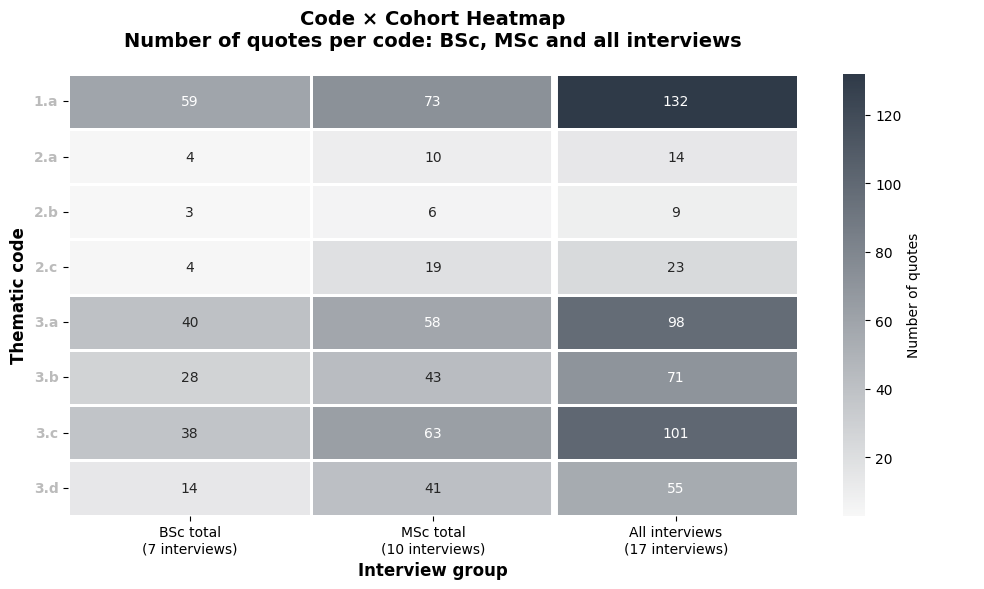


Thematic Code × Interview Type:
     BSc total\n(7 interviews)  MSc total\n(10 interviews)  \
1.a                         59                          73   
2.a                          4                          10   
2.b                          3                           6   
2.c                          4                          19   
3.a                         40                          58   
3.b                         28                          43   
3.c                         38                          63   
3.d                         14                          41   

     All interviews\n(17 interviews)  
1.a                              132  
2.a                               14  
2.b                                9  
2.c                               23  
3.a                               98  
3.b                               71  
3.c                              101  
3.d                               55  


In [5]:
code_matrix = agg_data['code_interview_matrix']

# Rows = codes, columns = interviews
df_codes = pd.DataFrame(code_matrix).T.fillna(0).astype(int)
df_codes = df_codes.reindex(sorted(df_codes.index))
df_codes = df_codes.reindex(columns=BSC_INTERVIEWS + MSC_INTERVIEWS, fill_value=0)

# Aggregate into BSc / MSc / All
col_bsc = f'BSc total\n({len(BSC_INTERVIEWS)} interviews)'
col_msc = f'MSc total\n({len(MSC_INTERVIEWS)} interviews)'
col_all = f'All interviews\n({len(BSC_INTERVIEWS) + len(MSC_INTERVIEWS)} interviews)'

df_summary = pd.DataFrame({
    col_bsc: df_codes[BSC_INTERVIEWS].sum(axis=1),
    col_msc: df_codes[MSC_INTERVIEWS].sum(axis=1),
    col_all: df_codes.sum(axis=1),
})

# Single-hue neutral colormap so it doesn't clash with the theme colours
heat_cmap = mcolors.LinearSegmentedColormap.from_list('quotes', ['#F7F7F7', '#2F3A48'])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df_summary, annot=True, fmt='d', cmap=heat_cmap, linewidths=1, linecolor='white',
            cbar_kws={'label': 'Number of quotes'}, ax=ax)

# Visual separator before the "All" column
ax.axvline(2, color='white', lw=5)

# Colour each code label with its theme shade
for lbl in ax.get_yticklabels():
    lbl.set_color(code_color(lbl.get_text()))
    lbl.set_fontweight('bold')
    lbl.set_rotation(0)
ax.tick_params(axis='x', rotation=0)

ax.set_title('Code × Cohort Heatmap\nNumber of quotes per code: BSc, MSc and all interviews',
             fontsize=14, fontweight='bold', pad=20)
ax.set_xlabel('Interview group', fontsize=12, fontweight='bold')
ax.set_ylabel('Thematic code', fontsize=12, fontweight='bold')
ax.legend(handles=theme_legend_handles(), loc='upper left', bbox_to_anchor=(1.22, 1),
          fontsize=9, frameon=False)

plt.tight_layout()
plt.show()

print("\nThematic Code × Interview Type:")
print(df_summary)

## Theme → Code → Finding-type Sankey diagram

**What it shows:** how the evidence (quotes) from the codebook flows into the Stage 2 findings.

**How to read it (left → right):**
1. **Themes** (left): the three top-level themes of the codebook.
2. **Codes** (middle): the sub-codes under each theme (e.g. 1.a under Theme 1).
3. **Finding types** (right): the kind of Stage 2 finding the quotes ended up supporting.

- **Ribbon width** = number of distinct quotes travelling along that connection.
- **Colour** = theme (hue) and specific code (shade). Colours are the same as in every other plot.
- A wide ribbon from a code to a finding type means many quotes tagged with that code were used as evidence in findings of that type.
- Node height = max(quotes in, quotes out). A quote can be tagged with several codes and support several findings, so totals are **not** additive across columns.
- A code with no ribbon to a finding type has never been used as evidence for that type.

**Why it matters:** it links the a-priori codebook structure to the patterns that emerged in Stage 2, e.g. which codes mostly produce alignment versus tension or contradiction.

In [6]:
FINDING_ORDER = ['alignment', 'tension', 'contradiction', 'subtlety',
                 'emerging_pattern', 'irrelevant_pattern']
finding_type_display = {'alignment': 'Alignment', 'contradiction': 'Contradiction',
                        'tension': 'Tension', 'subtlety': 'Subtlety',
                        'emerging_pattern': 'Emerging Pattern',
                        'irrelevant_pattern': 'Irrelevant Pattern'}


def draw_sankey(layers, flows, node_colors, flow_colors, layer_titles=None,
                figsize=(16, 9.5), node_width=0.025, gap_frac=0.03, title=None,
                explanation=None):
    """
    layers: list of lists of node names (one list per column, left → right)
    flows: list of (source, target, value) between adjacent layers
    node_colors: {node: colour}
    flow_colors: {(source, target): colour}
    """
    n_layers = len(layers)
    x_pos = np.linspace(0, 1, n_layers)
    order = {n: i for layer in layers for i, n in enumerate(layer)}
    layer_of = {n: li for li, layer in enumerate(layers) for n in layer}

    # Node value = max(incoming, outgoing)
    n_in, n_out = defaultdict(float), defaultdict(float)
    for s, t, v in flows:
        n_out[s] += v
        n_in[t] += v
    val = {n: max(n_in[n], n_out[n], 0.5) for layer in layers for n in layer}

    # Common scale across layers so ribbon widths are comparable; centre each layer
    layer_sums = [sum(val[n] for n in layer) for layer in layers]
    gap = gap_frac * max(layer_sums)
    layer_heights = [layer_sums[i] + gap * (len(layers[i]) - 1) for i in range(n_layers)]
    scale = max(layer_heights)

    pos = {}   # node -> (x, y_bottom, y_top)
    for li, layer in enumerate(layers):
        y = 1 - (scale - layer_heights[li]) / 2 / scale
        for n in layer:
            h = val[n] / scale
            pos[n] = (x_pos[li], y - h, y)
            y -= h + gap / scale

    # Ribbon offsets inside nodes, ordered to minimise crossings
    out_off, in_off = {}, {}
    for n in val:
        cur = pos[n][2]
        for s, t, v in sorted([f for f in flows if f[0] == n], key=lambda f: order[f[1]]):
            out_off[(s, t)] = cur
            cur -= v / scale
        cur = pos[n][2]
        for s, t, v in sorted([f for f in flows if f[1] == n], key=lambda f: order[f[0]]):
            in_off[(s, t)] = cur
            cur -= v / scale

    fig, ax = plt.subplots(figsize=figsize)

    for s, t, v in flows:
        h = v / scale
        sy_hi, ty_hi = out_off[(s, t)], in_off[(s, t)]
        sy_lo, ty_lo = sy_hi - h, ty_hi - h
        x0 = pos[s][0] + node_width
        x1 = pos[t][0]
        xm = (x0 + x1) / 2
        verts = [(x0, sy_hi), (xm, sy_hi), (xm, ty_hi), (x1, ty_hi),
                 (x1, ty_lo), (xm, ty_lo), (xm, sy_lo), (x0, sy_lo), (x0, sy_hi)]
        codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4,
                 Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
        ax.add_patch(mpatches.PathPatch(Path(verts, codes), facecolor=flow_colors[(s, t)],
                                        edgecolor='none', alpha=0.55))

    for n, (x, yb, yt) in pos.items():
        ax.add_patch(mpatches.Rectangle((x, yb), node_width, max(yt - yb, 0.002),
                                        facecolor=node_colors[n], edgecolor='black',
                                        linewidth=0.8, zorder=5))
        li = layer_of[n]
        count = int(round(val[n]))
        yc = (yb + yt) / 2
        if li == 0:       # left column: label to the left
            ax.text(x - 0.012, yc, textwrap.fill(n, 26) + f'\n{count} quotes',
                    ha='right', va='center', fontsize=9.5, fontweight='bold', zorder=6)
        elif li == n_layers - 1:   # right column: label to the right
            ax.text(x + node_width + 0.012, yc, f'{n}\n{count} quotes',
                    ha='left', va='center', fontsize=9.5, fontweight='bold', zorder=6)
        else:             # middle: label on the node
            ax.text(x + node_width / 2, yc, f'{n}\n{count}', ha='center', va='center',
                    fontsize=9, fontweight='bold', zorder=6,
                    bbox=dict(boxstyle='round,pad=0.2', fc='white', ec='none', alpha=0.8))

    if layer_titles:
        for li, t in enumerate(layer_titles):
            ax.text(x_pos[li] + node_width / 2, 1.04, t, ha='center', va='bottom',
                    fontsize=11, fontweight='bold')

    ax.legend(handles=theme_legend_handles(), loc='lower left', bbox_to_anchor=(0, -0.02),
              fontsize=9, title='Colour = theme (shade = code)', frameon=False)
    ax.set_xlim(-0.5, 1.3)
    ax.set_ylim(-0.02, 1.12)
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=14, fontweight='bold', pad=30)
    fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.2 if explanation else 0.05)
    if explanation:
        fig.text(0.02, 0.02, explanation, ha='left', va='bottom', fontsize=9.5,
                 bbox=dict(boxstyle='round,pad=0.6', fc='#F4F5F7', ec='#CCCCCC'))
    return fig, ax


# ---- Build layers, flows and colours ----
display_to_theme = {f'Theme {tid}: {name}': tid for tid, name in theme_names.items()}

themes_layer = sorted({t for t, _ in theme_code_flows})
codes_layer = sorted({c for _, c in theme_code_flows})
present = {f for _, f in code_finding_flows}
finding_keys = [f for f in FINDING_ORDER if f in present] + sorted(present - set(FINDING_ORDER))
findings_layer = [finding_type_display.get(f, f) for f in finding_keys]

sankey_flows, flow_colors = [], {}
for (theme, code), qids in theme_code_flows.items():
    sankey_flows.append((theme, code, len(qids)))
    flow_colors[(theme, code)] = code_color(code)
for (code, ftype), qids in code_finding_flows.items():
    fdisp = finding_type_display.get(ftype, ftype)
    sankey_flows.append((code, fdisp, len(qids)))
    flow_colors[(code, fdisp)] = code_color(code)

node_colors = {}
for t in themes_layer:
    node_colors[t] = THEME_COLOR.get(display_to_theme.get(t), NEUTRAL)
for c in codes_layer:
    node_colors[c] = code_color(c)
for f in findings_layer:
    node_colors[f] = FINDING_COLOR

explanation = (
    "How to read this diagram (left → right)\n"
    "• Themes → Codes → Finding types: each ribbon shows quotes moving from a theme, to the code they were tagged with, "
    "to the type of Stage 2 finding they support.\n"
    "• Ribbon width = number of distinct quotes. Colour = theme (hue) and code (shade).\n"
    "• Example: a wide ribbon from a code to 'Tension' means many quotes with that code were used as evidence in tension findings.\n"
    "• A quote can carry several codes and support several findings, so counts are not additive across columns."
)

fig, ax = draw_sankey(
    layers=[themes_layer, codes_layer, findings_layer],
    flows=sankey_flows,
    node_colors=node_colors,
    flow_colors=flow_colors,
    layer_titles=['Themes\n(codebook)', 'Codes\n(codebook)', 'Finding types\n(Stage 2)'],
    title='From codebook to findings: Theme → Code → Finding type\nRibbon width = number of quotes',
    explanation=explanation,
)
plt.show()

print("\nTheme → Code Flows (by quote count):")
for (theme, code), ids in sorted(theme_code_flows.items(), key=lambda x: len(x[1]), reverse=True):
    print(f"  {theme} → {code}: {len(ids)} quotes")

print("\nCode → Finding Type Flows (by quote count):")
for (code, ftype), ids in sorted(code_finding_flows.items(), key=lambda x: len(x[1]), reverse=True)[:20]:
    print(f"  {code} → {ftype}: {len(ids)} quotes")
    if len(ids) <= 3:
        print(f"    Quote IDs: {ids}")

ZeroDivisionError: float division by zero

## 4. Quote Overlap Across Codes Visualization

**Visualization**: A network showing how quotes appear across multiple codes.

**Key insights**:
- Identify which quotes are coded to multiple codes (same quote, different interpretations)
- Shows the interconnectedness of codes based on real quote data
- Reveals potential ambiguities or rich multi-faceted quotes
- Data extracted from within-interview duplicate citations

In [ ]:
# Code network visualization with unified theme/code colours
if len(all_codes_list) > 0 and G_overlap.number_of_nodes() > 0:
    # Calculate code totals from co-occurrence
    code_total_quotes = {}
    for c in all_codes_list:
        if c in G_overlap:
            neighbors = list(G_overlap.neighbors(c))
            total = sum(G_overlap[c][nbr]['weight'] for nbr in neighbors) if neighbors else 0
            code_total_quotes[c] = total
        else:
            code_total_quotes[c] = 0

    # Node colours from the shared scheme (theme hue, code shade)
    node_colors = [code_color(c) for c in G_overlap.nodes()]
    node_sizes = [400 + code_total_quotes[c]*40 for c in G_overlap.nodes()]

    # Layout and draw
    pos_overlap = nx.spring_layout(G_overlap, k=2.2, iterations=100, seed=42)
    fig, ax = plt.subplots(figsize=(13, 11))

    nx.draw_networkx_nodes(G_overlap, pos_overlap, node_color=node_colors, node_size=node_sizes,
                           alpha=0.9, edgecolors='black', linewidths=1.8, ax=ax)

    weights_overlap = [G_overlap[u][v]['weight'] for u,v in G_overlap.edges()]
    max_w = max(weights_overlap) if weights_overlap else 1
    nx.draw_networkx_edges(G_overlap, pos_overlap, alpha=0.5, edge_color='gray',
                           width=[2+(w/max_w)*8 for w in weights_overlap], ax=ax)

    nx.draw_networkx_labels(G_overlap, pos_overlap, font_size=11, font_weight='bold', ax=ax)
    nx.draw_networkx_edge_labels(G_overlap, pos_overlap,
                                 {(u,v): int(G_overlap[u][v]['weight']) for u,v in G_overlap.edges()},
                                 font_size=9, ax=ax)

    # Legend
    handles = theme_legend_handles()
    handles.append(Line2D([0],[0], marker='o', color='w', markerfacecolor='gray', markersize=8,
                          label='Node size ∝ total shared quotes'))
    ax.legend(handles=handles, loc='upper left', fontsize=9, title='Legend (colour = theme, shade = code)')
    ax.set_title('Code Network: Shared Quote Connections\n(Edge thickness = number of quotes coded to both codes)',
                 fontweight='bold', fontsize=12, pad=15)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    print("\nCode Network Statistics:")
    print(f"  Nodes (codes): {G_overlap.number_of_nodes()}")
    print(f"  Edges (co-occurrences): {G_overlap.number_of_edges()}")
else:
    print("Insufficient data for code network visualization")